# Studi Kasus: *Model Klasifikasi Status Pesanan untuk Deteksi Dini Risiko Pembatalan Berdasarkan Atribut Pengiriman dan Pembayaran*

# A. Bussiness Understanding

### 1. Masalah
Data: pesanan satu toko Shopee, Des 2023 sampai Nov 2025, **20.759 pesanan**. Sebanyak **2.830 (13,63%)** dibatalkan. Setiap pembatalan membuang waktu pemrosesan dan menahan stok, sementara penjual baru tahu setelah pesanan batal dan belum tahu faktor apa yang paling terkait. Proyek ini membangun model klasifikasi untuk **deteksi dini risiko pembatalan** dari informasi yang tersedia saat checkout.

### 2. Pertanyaan yang Ingin Dijawab
1. Bagaimana pola penjualan dan pembatalan menurut waktu, wilayah, kategori, metode pembayaran, opsi kirim, ongkir, dan diskon?
2. Faktor apa yang berasosiasi dengan pembatalan setelah faktor lain dikontrol?
3. Seberapa baik pembatalan dapat diprediksi dari informasi saat pesanan masuk?
4. Segmen mana yang layak diprioritaskan untuk penyesuaian kebijakan toko?

### 3. Metode
1. **Kerangka kerja:** CRISP-DM.
2. **Target:** biner, Batal = 1 dan tidak batal = 0 (pesanan yang masih berjalan dikeluarkan).
3. **EDA:** tingkat pembatalan per segmen, uji statistik, ukuran efek, dan regresi multivariat.
4. **Model:** regresi logistik, random forest, gradient boosting, dibandingkan dengan baseline sederhana.
5. **Validasi:** pemisahan data latih, validasi, dan uji berdasarkan waktu; threshold dipilih pada data validasi.
6. **Ketidakseimbangan kelas:** class weight atau resampling hanya pada data latih.
7. **Pencegahan data leakage:** hanya fitur yang tersedia saat checkout; Alasan Pembatalan, Total Pembayaran, dan kolom ongkir tidak dipakai.
8. **Interpretasi:** SHAP atau permutation importance.
9. **Catatan:** temuan bersifat asosiatif, bukan sebab-akibat.

### 4. Metrik
| Level | Metrik |
|---|---|
| Utama | F1-score |
| Pendukung | PR-AUC, Recall, Precision, ROC-AUC, F2-score, MCC, confusion matrix |
| Kalibrasi | Brier score, reliability curve |
| Stabilitas | Variasi F1 dan PR-AUC antar periode, CI 95% bootstrap |
| EDA | Tingkat pembatalan keseluruhan (2.830 ÷ 20.759 = 13,63%) dan per segmen |

**Kriteria berhasil:** F1-score model lebih baik daripada baseline pada data uji, dengan target awal Recall ≥ 0,70 dan Precision ≥ 0,30 pada threshold dari data validasi. Accuracy tidak dipakai karena kelas tidak seimbang.

## B. Data Gathering

### 1 Sumber Data
Dataset yang digunakan dalam penelitian ini diperoleh dari Kaggle dengan judul *Indonesia E-Commerce Sales and Shipping 2023–2025*. Dataset dapat diakses melalui tautan berikut:

[Indonesia E-Commerce Sales and Shipping 2023–2025](https://www.kaggle.com/datasets/bakitacos/indonesia-e-commerce-sales-and-shipping-20232025)

### 2 Metode Pengumpulan Data
Pengumpulan data dilakukan dengan mengunduh dataset dari Kaggle menggunakan Python melalui modul `kagglehub` yang dipanggil oleh fungsi `download_and_process_kaggle_data()` pada file `utils/download_dataset.py`. Proses pengunduhan dijalankan secara otomatis apabila file dataset yang dibutuhkan belum tersedia di direktori lokal.

### 3 Pemuatan Data
Data yang telah disiapkan dibaca menggunakan pustaka `pandas` melalui fungsi `pd.read_csv()`. Dataset yang digunakan pada tahap ini adalah `all_months_clean.csv`, yang disimpan secara lokal pada direktori `dataset/`.

Setelah data berhasil dimuat, dilakukan pemeriksaan awal terhadap jumlah baris, jumlah kolom, penggunaan memori, dan beberapa sampel data untuk memahami struktur dataset sebelum memasuki tahap *Data Understanding*.

### 4 Pengelolaan Dataset
Dataset disimpan secara lokal dan direktori `dataset/` dikecualikan dari pelacakan Git melalui file `.gitignore`. Dengan demikian, file dataset mentah tidak perlu diunggah ke repository GitHub. Proses pengunduhan dapat dilakukan kembali oleh pengguna yang menjalankan notebook sesuai konfigurasi dan akses Kaggle yang diperlukan.

### 5 Tujuan Pengumpulan Data
Data dikumpulkan sebagai dasar untuk menganalisis atribut transaksi, pembayaran, dan pengiriman yang berpotensi berkaitan dengan status pesanan. Data tersebut selanjutnya akan digunakan dalam penelitian mengenai klasifikasi status pesanan untuk mendeteksi risiko pembatalan pada transaksi e-commerce.

## kode pemanggilan library
### Download dataset untuk pertama kali jika dataset belum di unduh

In [ ]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from utils.download_dataset import download_and_process_kaggle_data

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 25)
pd.set_option('display.width', 120)
pd.set_option('display.float_format', '{:,.2f}'.format)

DATASET_FILE = "./dataset/all_months_clean.csv"
KAGGLE_URL = "https://www.kaggle.com/datasets/bakitacos/indonesia-e-commerce-sales-and-shipping-20232025/data?select=all_months_clean.csv"

# Unduh dan proses via modul terpisah jika file belum tersedia
if not os.path.exists(DATASET_FILE):
    print(f"File '{DATASET_FILE}' belum ada. Menjalankan proses pengunduhan...")
    download_and_process_kaggle_data(KAGGLE_URL)

# Membaca data yang sudah bersih
df = pd.read_csv(DATASET_FILE)

print(f"Dataset berhasil dimuat  : {df.shape[0]:,} baris x {df.shape[1]} kolom")
print(f"Penggunaan Memori        : {df.memory_usage(deep=True).sum() / (1024**2):.2f} MB")

df.head(8)

/home/morxidia/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dataset berhasil dimuat  : 20,848 baris x 19 kolom
Penggunaan Memori        : 13.70 MB


,order_id,total_qty,total_weight_gr,total_returned_qty,Total Diskon,product_categories,num_product_categories,Status Pesanan,Alasan Pembatalan,Opsi Pengiriman,Metode Pembayaran,Kota/Kabupaten,Provinsi,Ongkos Kirim Dibayar oleh Pembeli,Estimasi Potongan Biaya Pengiriman,Total Pembayaran,Perkiraan Ongkos Kirim,Waktu Pesanan Dibuat,source_file
0,ORD_0000001,2,2000,0,0,Celengan,1,Selesai,NaN,Reguler (Cashless)-SPX Standard,Saldo ShopeePay,KOTA SERANG,BANTEN,0,10000,38300,10000,2024-04-01 00:15,AprilSales2024.xlsx
1,ORD_0000002,1,500,0,0,Celengan,1,Selesai,NaN,Hemat Kargo-SPX Hemat,COD (Bayar di Tempat),KOTA SEMARANG,JAWA TENGAH,0,14500,18576,14500,2024-04-01 01:47,AprilSales2024.xlsx
2,ORD_0000003,1,500,0,0,Celengan,1,Selesai,NaN,Hemat Kargo-SPX Hemat,SeaBank Bayar Instan,KAB. BOGOR,JAWA BARAT,0,8000,7069,8000,2024-04-01 04:25,AprilSales2024.xlsx
3,ORD_0000004,2,400,0,0,Mangkok Sambal / Saus,1,Selesai,NaN,Hemat Kargo-SPX Hemat,COD (Bayar di Tempat),KOTA JAMBI,JAMBI,0,20000,32200,20000,2024-04-01 04:41,AprilSales2024.xlsx
4,ORD_0000005,3,3600,0,0,"Keranjang, Other, Tempat Nasi",3,Batal,Dibatalkan oleh Pembeli. Alasan: Ubah Pesanan ...,Hemat Kargo-SPX Hemat,COD (Bayar di Tempat),KOTA TANGERANG,BANTEN,0,0,0,8000,2024-04-01 06:12,AprilSales2024.xlsx
5,ORD_0000006,2,1000,0,0,Celengan,1,Selesai,NaN,Hemat Kargo-SPX Hemat,SPayLater,KAB. BANDUNG,JAWA BARAT,0,10000,40996,10000,2024-04-01 07:09,AprilSales2024.xlsx
6,ORD_0000007,1,1700,0,0,Nampan / Tray,1,Batal,Dibatalkan oleh Pembeli. Alasan: Ubah Pesanan ...,Hemat Kargo-SPX Hemat,SPayLater,KOTA TANGERANG,BANTEN,0,0,0,16000,2024-04-01 07:23,AprilSales2024.xlsx
7,ORD_0000008,1,500,0,0,Celengan,1,Selesai,NaN,Hemat Kargo-SPX Hemat,Online Payment,KAB. BOGOR,JAWA BARAT,0,8000,18280,8000,2024-04-01 07:33,AprilSales2024.xlsx


### 1. Evaluasi & Penanganan Kualitas Data (Data Quality)

Tahap ini berfokus pada identifikasi dan penanganan anomali pada dataset mentah (*raw data*). Pendekatan yang digunakan bertujuan untuk membersihkan data tanpa menghilangkan sinyal penting atau merusak representativitas populasi transaksi.

**A. Missing Values (Data Kosong)**
* **Temuan:** Terdapat **9,5% data kosong** pada atribut `Waktu Pesanan Dibuat`. Kehilangan pencatatan waktu ini diduga kuat berkaitan dengan anomali sistemik (misal: *timeout* pada *payment gateway*).
* **Tindakan:** Tidak dilakukan penghapusan baris (*drop*) untuk mencegah bias seleksi. Kekosongan ini diubah menjadi fitur prediktif:
  * Dibuat fitur biner **`Is_Missing_Waktu`** untuk menandai baris yang cacat sistem.
  * Fitur turunan `Jam_Pesan` dan `Hari_Pesan` yang kosong diimputasi dengan nilai **-1** agar algoritma memetakannya ke dalam klaster anomali tersendiri.

**B. Outlier (Pencilan Data Logistik)**
* **Temuan:** Terdapat rentang nilai yang sangat ekstrem pada kolom `total_weight_gr` (hingga puluhan/ratusan kilogram) dan `Perkiraan Ongkos Kirim`.
* **Tindakan:** Outlier ini **tidak dihapus**. Rent

In [2]:
# 2. Audit Duplikasi Data
print("AUDIT DUPLIKASI DATA ")
duplicate_mask = df.duplicated(keep=False)
duplicate_count = df.duplicated().sum()

print(f"Total baris duplikat (exact duplicates): {duplicate_count}")

if duplicate_count > 0:
    duplicates_df = df[duplicate_mask].sort_values(by=df.columns.tolist())
    display(duplicates_df)
else:
    print("Tidak ditemukan baris yang sepenuhnya identik pada dataset.")

AUDIT DUPLIKASI DATA 
Total baris duplikat (exact duplicates): 0
Tidak ditemukan baris yang sepenuhnya identik pada dataset.


 TABEL AUDIT MISSING DATA EKSPLISIT & NILAI NOL 


,Null Eksplisit (n),Null Eksplisit (%),Nilai Nol / Rp 0 (n),Nilai Nol / Rp 0 (%)
total_returned_qty,0,0.00,20691,99.25
Total Diskon,0,0.00,20713,99.35
Alasan Pembatalan,18018,86.43,0,0.00
Ongkos Kirim Dibayar oleh Pembeli,0,0.00,14552,69.80
Estimasi Potongan Biaya Pengiriman,0,0.00,5309,25.47
Total Pembayaran,0,0.00,2892,13.87
Waktu Pesanan Dibuat,1980,9.50,0,0.00


Missing Values Summary:


,Feature,Missing Count,Missing Percentage (%)
0,Alasan Pembatalan,18018,86.43
1,Waktu Pesanan Dibuat,1980,9.50


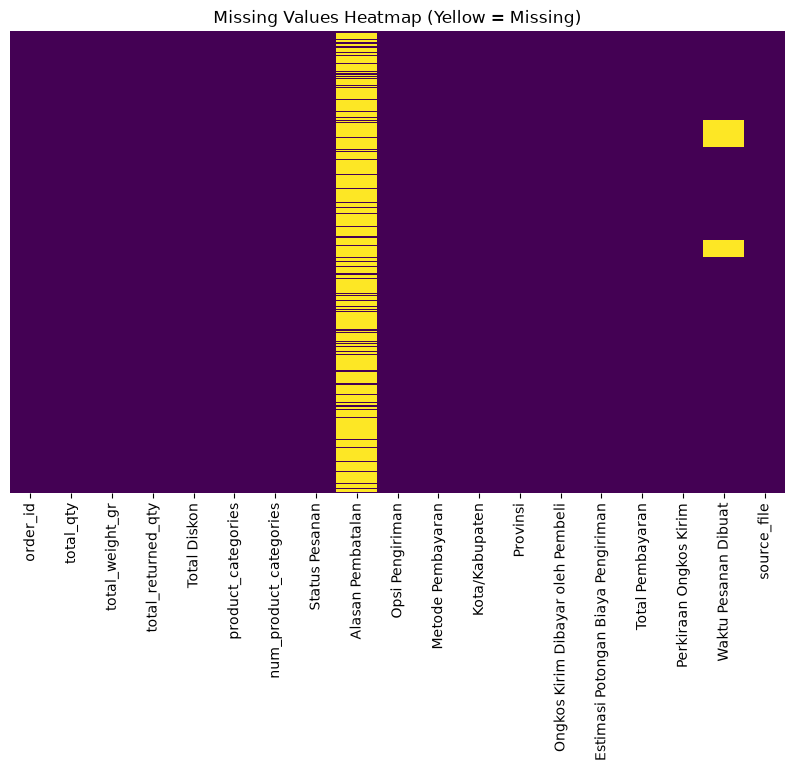

In [3]:
# 1. Audit Missing Eksplisit vs Implisit
num_cols = df.select_dtypes(include=[np.number]).columns

missing_audit = pd.DataFrame({
    "Null Eksplisit (n)": df.isna().sum(),
    "Null Eksplisit (%)": (df.isna().mean() * 100).round(2),
    "Nilai Nol / Rp 0 (n)": [(df[c] == 0).sum() if c in num_cols else 0 for c in df.columns],
    "Nilai Nol / Rp 0 (%)": [round((df[c] == 0).mean() * 100, 2) if c in num_cols else 0.0 for c in df.columns]
})

print(" TABEL AUDIT MISSING DATA EKSPLISIT & NILAI NOL ")
display_audit = missing_audit[(missing_audit["Null Eksplisit (n)"] > 0) | (missing_audit["Nilai Nol / Rp 0 (n)"] > 0)]

if not display_audit.empty:
    display(display_audit)
else:
    print("Tidak ditemukan missing values atau nilai nol.\n")

# Calculate count and percentage of missing values
missing_data = df.isna().sum()
missing_data = missing_data[missing_data > 0].reset_index()
missing_data.columns = ['Feature', 'Missing Count']
missing_data['Missing Percentage (%)'] = (missing_data['Missing Count'] / len(df)) * 100

print("Missing Values Summary:")
display(missing_data.sort_values(by='Missing Percentage (%)', ascending=False))

# Visualize missing data patterns
plt.figure(figsize=(10, 6))
sns.heatmap(df.isna(), cbar=False, cmap='viridis', yticklabels=False)
plt.title("Missing Values Heatmap (Yellow = Missing)")
plt.show()

Outlier Detection Summary (IQR Method):


,Outlier Count,Percentage (%),Lower Bound,Upper Bound
total_qty,"2,614.00",12.54,-0.50,3.50
total_weight_gr,"2,448.00",11.74,"-1,650.00","3,550.00"
Ongkos Kirim Dibayar oleh Pembeli,"4,048.00",19.42,"-4,500.00","7,500.00"
Estimasi Potongan Biaya Pengiriman,788.00,3.78,"-22,500.00","37,500.00"
Total Pembayaran,"2,309.00",11.08,"-28,700.00","83,780.00"
Perkiraan Ongkos Kirim,"1,815.00",8.71,"-10,000.00","38,000.00"


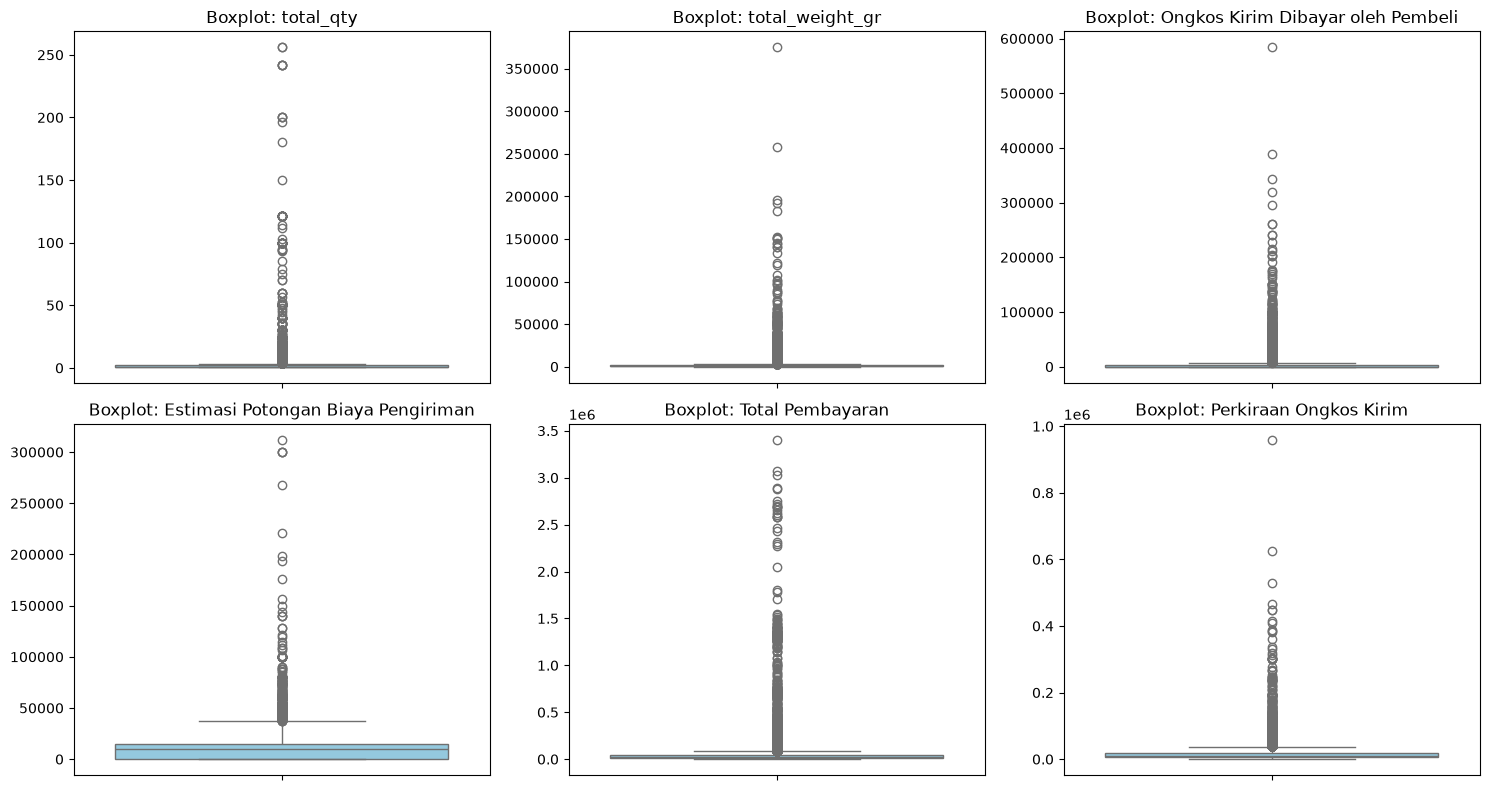

In [4]:
# Define numeric columns for outlier detection based on dataset schema
numeric_cols = [
    'total_qty', 'total_weight_gr', 'Ongkos Kirim Dibayar oleh Pembeli', 
    'Estimasi Potongan Biaya Pengiriman', 'Total Pembayaran', 'Perkiraan Ongkos Kirim'
]

# Function to calculate outliers using Tukey's IQR
def count_outliers_iqr(dataframe, columns):
    outlier_summary = {}
    for col in columns:
        Q1 = dataframe[col].quantile(0.25)
        Q3 = dataframe[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        
        outliers = dataframe[(dataframe[col] < lower_bound) | (dataframe[col] > upper_bound)]
        outlier_summary[col] = {
            'Outlier Count': len(outliers),
            'Percentage (%)': round((len(outliers) / len(dataframe)) * 100, 2),
            'Lower Bound': lower_bound,
            'Upper Bound': upper_bound
        }
    return pd.DataFrame(outlier_summary).T

outlier_df = count_outliers_iqr(df, numeric_cols)
print("Outlier Detection Summary (IQR Method):")
display(outlier_df)

# Visualize numeric distributions with boxplots
plt.figure(figsize=(15, 8))
for i, col in enumerate(numeric_cols, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(y=df[col], color='skyblue')
    plt.title(f"Boxplot: {col}")
    plt.ylabel("")
plt.tight_layout()
plt.show()

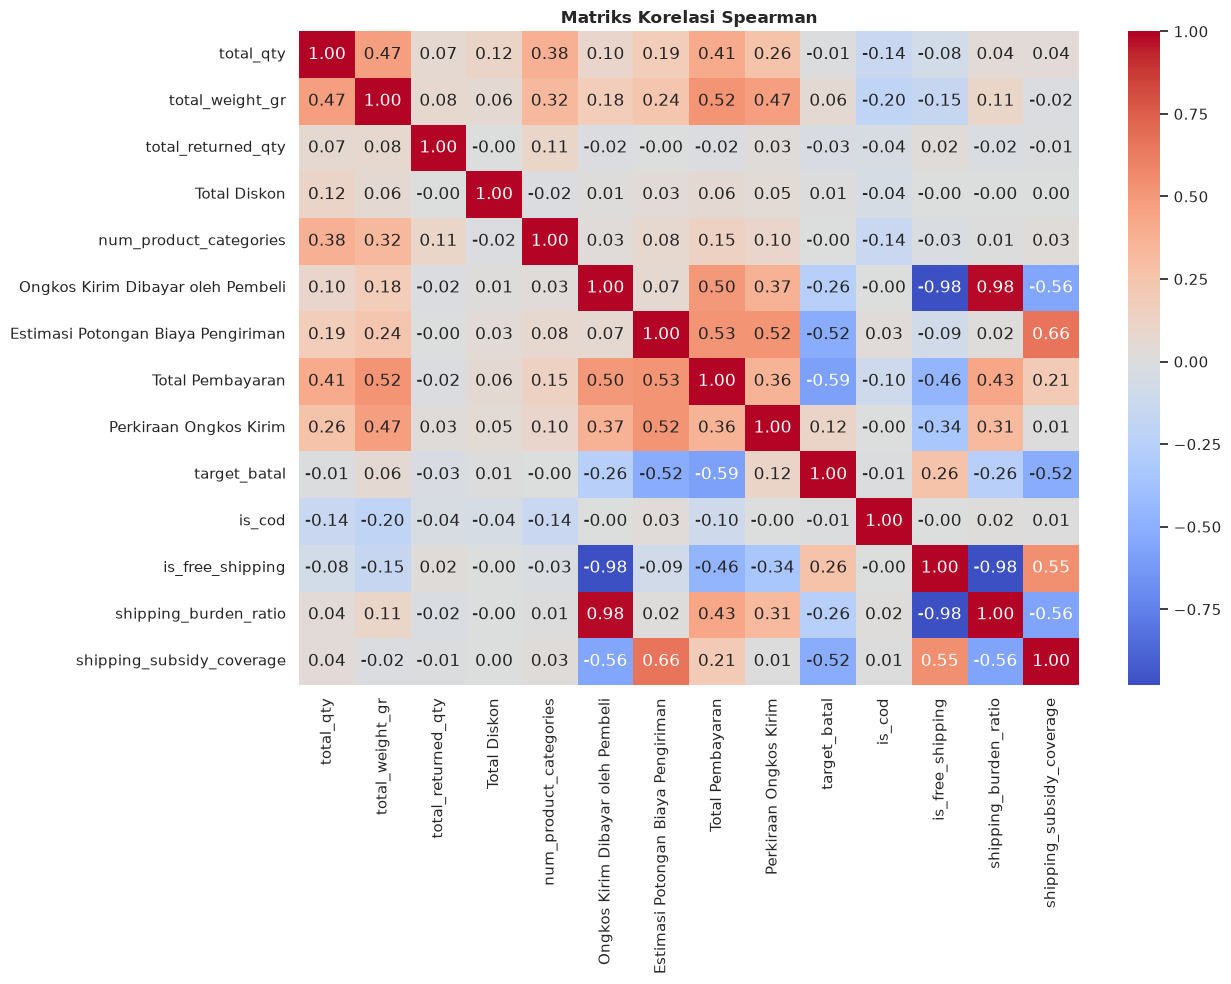

In [18]:
# 1. Hitung korelasi Spearman langsung dari kolom numerik asli
corr = df.select_dtypes(include="number").corr(method="spearman")

# 2. Tampilkan heatmap matriks 2 sumbu (X dan Y)
plt.figure(figsize=(13, 10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, cbar=True)
plt.title("Matriks Korelasi Spearman", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

### 2. Exploratory Data Analysis (EDA): Mengungkap Pola Risiko

Fase eksplorasi ini bertujuan untuk memahami karakteristik distribusi target dan menemukan variabel prediktor yang memiliki korelasi terkuat terhadap risiko pembatalan. Temuan di tahap ini secara langsung mendikte keputusan arsitektur pemodelan.


In [5]:
# Pengaturan visualisasi
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Load dataset
df = pd.read_csv("./dataset/all_months_clean.csv")

# Filter hanya pesanan Selesai dan Batal, lalu buat target biner
df_model = df[df['Status Pesanan'].isin(['Selesai', 'Batal'])].copy()
df_model['Is_Batal'] = (df_model['Status Pesanan'] == 'Batal').astype(int)

# Rekayasa Fitur Waktu Pemesanan (Mengatasi Missing Values dengan membuang baris kosong pada waktu)
df_model = df_model.dropna(subset=['Waktu Pesanan Dibuat']).copy()
df_model['Waktu Pesanan Dibuat'] = pd.to_datetime(df_model['Waktu Pesanan Dibuat'])
df_model['Jam_Pesan'] = df_model['Waktu Pesanan Dibuat'].dt.hour
df_model['Hari_Pesan'] = df_model['Waktu Pesanan Dibuat'].dt.dayofweek



**A. Analisis Target Utama: Ketidakseimbangan Kelas (Class Imbalance)**
* **Observasi:** Distribusi target sangat timpang; mayoritas pesanan (±85%) berstatus **"Selesai"**, sementara minoritas (±15%) berstatus **"Batal"**.
* **Implikasi Pemodelan:** Menggunakan algoritma standar pada data ini akan memicu *accuracy paradox* (model selalu menebak "Selesai" untuk mengamankan akurasi semu). Oleh karena itu:
  1. Akurasi umum (Global Accuracy) diabaikan. Evaluasi model akan berfokus pada metrik **F1-Score, Precision, Recall, dan ROC-AUC**.
  2. Dibutuhkan intervensi **SMOTE** pada matriks pelatihan untuk menyeimbangkan batas keputusan kelas minoritas.

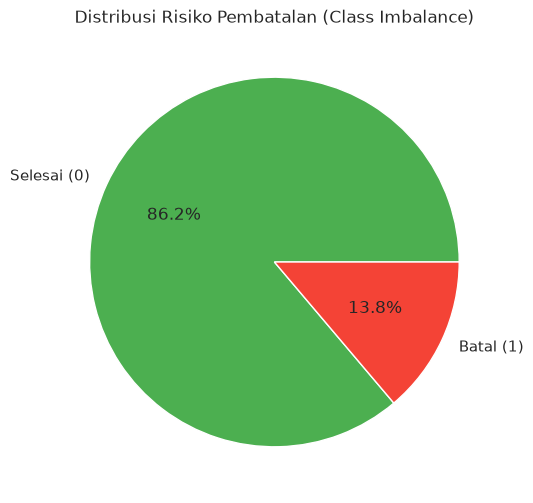

In [6]:
# A. Distribusi Target Kelas
plt.figure(figsize=(6, 6))
df_model['Is_Batal'].value_counts().plot.pie(autopct='%1.1f%%', labels=['Selesai (0)', 'Batal (1)'], colors=['#4CAF50', '#F44336'])
plt.title("Distribusi Risiko Pembatalan (Class Imbalance)")
plt.ylabel("")
plt.show()


**B. Analisis Bivariat: Polarisasi Metode Pembayaran**
* **Observasi:** Metode *Cash on Delivery* (COD) menjadi episentrum utama penumpukan pesanan batal (hambatan komitmen rendah). Sebaliknya, transaksi prabayar absolut (Transfer Bank terverifikasi, E-Wallet) didominasi oleh pesanan selesai karena adanya *sunk cost*.
* **Implikasi Pemodelan:** Metode pembayaran adalah prediktor kategorikal paling krusial. Proses *One-Hot Encoding* akan menerjemahkan perilaku impulsif COD ini menjadi bobot matematis yang tinggi di dalam model.

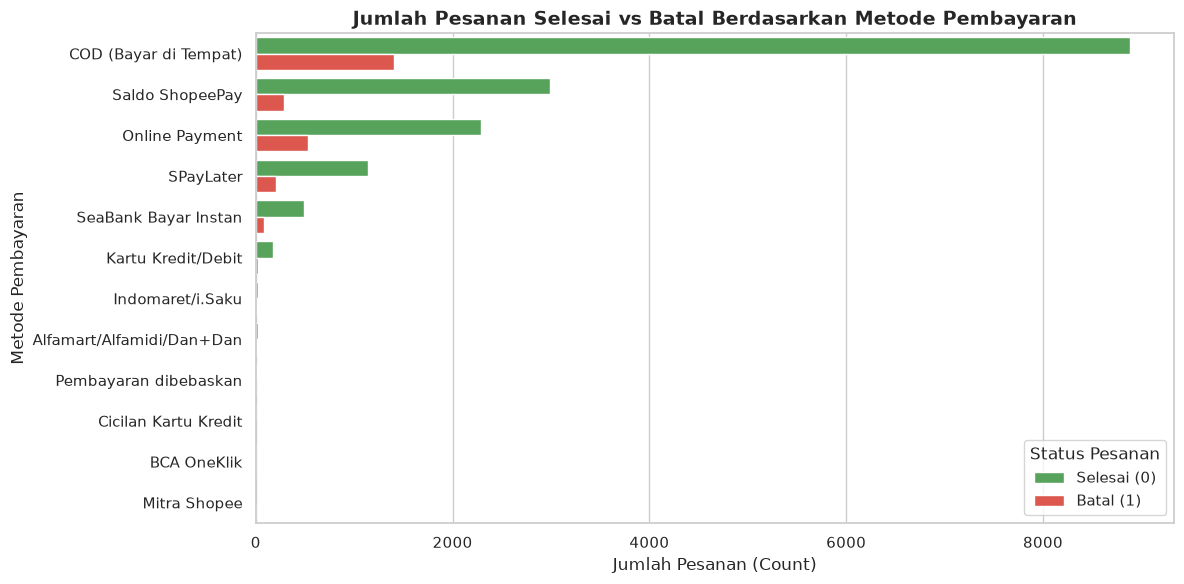

In [7]:
# B. Bivariate Analysis: Perbandingan Selesai vs Batal berdasarkan Metode Pembayaran
plt.figure(figsize=(12, 6))

# Menggunakan countplot untuk menghitung jumlah baris per kategori
# Urutkan berdasarkan metode pembayaran yang paling sering digunakan
order_metode = df_model['Metode Pembayaran'].value_counts().index

sns.countplot(
    data=df_model, 
    y='Metode Pembayaran', 
    hue='Is_Batal', 
    palette={0: '#4CAF50', 1: '#F44336'}, # Hijau untuk Selesai, Merah untuk Batal
    order=order_metode
)

plt.title("Jumlah Pesanan Selesai vs Batal Berdasarkan Metode Pembayaran", fontsize=14, fontweight='bold')
plt.xlabel("Jumlah Pesanan (Count)", fontsize=12)
plt.ylabel("Metode Pembayaran", fontsize=12)

# Menyesuaikan Legenda
plt.legend(title='Status Pesanan', labels=['Selesai (0)', 'Batal (1)'], loc='lower right')

plt.tight_layout()
plt.show()


**C. Analisis Distribusi Spasial: Anomali Logistik (Berat & Ongkir)**
* **Observasi:** Distribusi scatter plot mengungkap bahwa pesanan batal melonjak secara eksponensial ketika **total_weight_gr** menyentuh angka ekstrem (kapasitas berlebih) atau ketika **Perkiraan Ongkos Kirim** melonjak tidak proporsional (*shipping cost shock*). 
* **Implikasi Pemodelan:** Fitur-fitur ini memetakan batasan toleransi logistik secara sangat jelas, menjadikannya koordinat yang sempurna untuk algoritma pemisah batas seperti KNN. Namun, karena *outlier* logistik ini ekstrem tetapi bermakna, fitur numerik wajib melewati **RobustScaler** agar rentang skalanya aman dikomputasi oleh model.

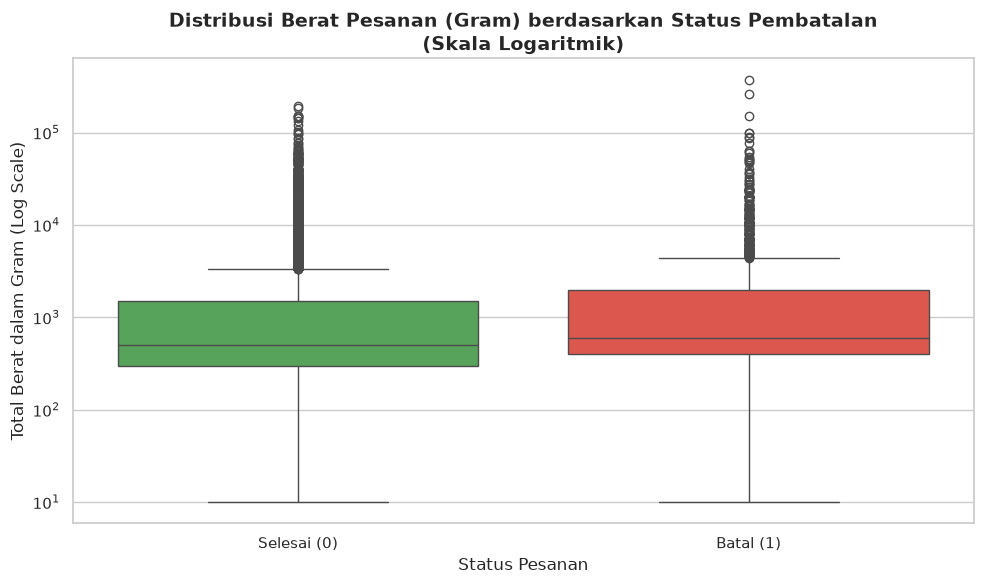

In [8]:
# C. Distribusi Numerik Logistik (Melihat Outlier pada Berat Pesanan terhadap Target)
plt.figure(figsize=(10, 6))

# Tambahkan hue='Is_Batal' dan legend=False untuk kompatibilitas versi Seaborn terbaru
sns.boxplot(
    x='Is_Batal', 
    y='total_weight_gr', 
    hue='Is_Batal', 
    data=df_model, 
    palette={0: '#4CAF50', 1: '#F44336'},
    legend=False
)

plt.yscale('log')
plt.title("Distribusi Berat Pesanan (Gram) berdasarkan Status Pembatalan\n(Skala Logaritmik)", fontsize=14, fontweight='bold')
plt.xticks([0, 1], ['Selesai (0)', 'Batal (1)'])
plt.ylabel("Total Berat dalam Gram (Log Scale)", fontsize=12)
plt.xlabel("Status Pesanan", fontsize=12)

plt.tight_layout()
plt.show()

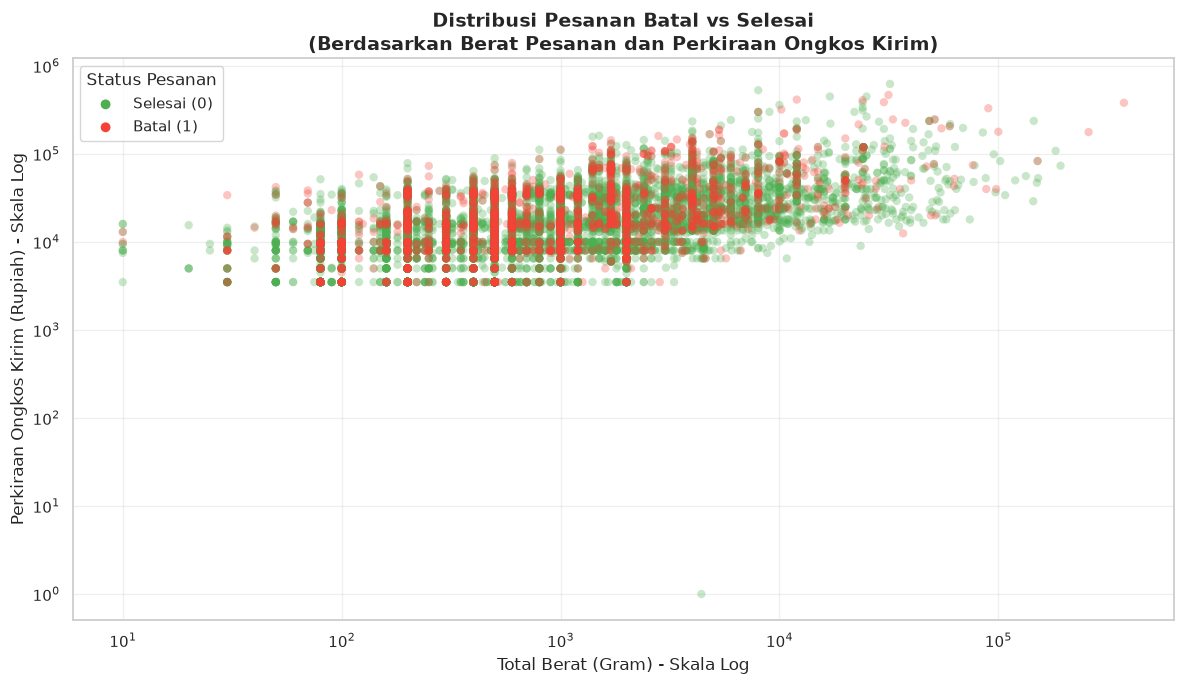

In [9]:
# Memisahkan data berdasarkan kelas target
df_selesai = df_model[df_model['Is_Batal'] == 0]
df_batal = df_model[df_model['Is_Batal'] == 1]

plt.figure(figsize=(12, 7))

# 1. Plot layer pertama: Pesanan Selesai (Hijau) di latar belakang (zorder=1)
plt.scatter(
    x=df_selesai['total_weight_gr'], 
    y=df_selesai['Perkiraan Ongkos Kirim'], 
    c='#4CAF50', 
    label='Selesai (0)', 
    alpha=0.3, 
    edgecolors='none',
)

# 2. Plot layer kedua: Pesanan Batal (Merah) di layer atas (zorder=2)
plt.scatter(
    x=df_batal['total_weight_gr'], 
    y=df_batal['Perkiraan Ongkos Kirim'], 
    c='#F44336', 
    label='Batal (1)', 
    alpha=0.3, 
    edgecolors='none',
)

# Menggunakan skala logaritmik agar titik tidak bertumpuk di nilai rendah
plt.xscale('log')
plt.yscale('log')

plt.title("Distribusi Pesanan Batal vs Selesai\n(Berdasarkan Berat Pesanan dan Perkiraan Ongkos Kirim)", fontsize=14, fontweight='bold')
plt.xlabel("Total Berat (Gram) - Skala Log", fontsize=12)
plt.ylabel("Perkiraan Ongkos Kirim (Rupiah) - Skala Log", fontsize=12)

# Mengatur tampilan legenda
legenda = plt.legend(title='Status Pesanan', loc='upper left')
for handle in legenda.legend_handles:
    handle.set_alpha(1)
    handle.set_sizes([50])

plt.grid(alpha=0.3, zorder=0)
plt.tight_layout()
plt.show()

# Data Processing
Tahap pembersihan dan rekayasa fitur difokuskan untuk mencegah kebocoran data, menangani outlier logistik, dan mengamankan representativitas sampel.

1. Penanganan Data Kosong (Mitigasi Bias)
Menghapus 9,5% data Waktu Pesanan Dibuat yang kosong akan memicu bias seleksi. Sebagai solusi, kekosongan ini diubah menjadi fitur Is_Missing_Waktu. Nilai jam/hari yang hilang diimputasi dengan -1 agar model memetakannya sebagai anomali sistemik, menjaga 100% keutuhan populasi latih.

2. Rekayasa Fitur Temporal Data waktu mentah diekstrak menjadi Jam_Pesan dan Hari_Pesan untuk menangkap pola perilaku pembeli, seperti impulsivitas belanja pada jam-jam tertentu yang berpotensi memicu pembatalan.

3. Eliminasi Fitur Berbahaya
Kolom-kolom berikut dihapus untuk menjaga validitas model:Alasan Pembatalan: Memicu data leakage (baru diketahui setelah batal).Total Pembayaran: Bias sistem (selalu tercatat 0 jika pesanan batal).No. Pesanan & Username: Data unik yang tidak membawa pola prediktif.
4. Matriks Prediktor Akhir Dataset kini siap untuk tahap Encoding dan Scaling, berfokus pada metrik awal checkout: Kategorikal: Metode Pembayaran, Opsi Pengiriman. Numerikal: total_weight_gr, Perkiraan Ongkos Kirim, Jam_Pesan, Hari_Pesan, Is_Missing_Waktu.

In [10]:
# 1. Load Dataset dan Filter Kelas Target Utama
df_clean = df[df['Status Pesanan'].isin(['Selesai', 'Batal'])].copy()

# 2. Pembuatan Target Biner
df_clean['Is_Batal'] = (df_clean['Status Pesanan'] == 'Batal').astype(int)

# 3. Penanganan Missing Values & Rekayasa Fitur Temporal
# Mengekstrak informasi kekosongan menjadi fitur baru
df_clean['Is_Missing_Waktu'] = df_clean['Waktu Pesanan Dibuat'].isnull().astype(int)

# Ekstraksi ke format waktu, lalu imputasi data yang kosong (NaT) dengan koordinat anomali (-1)
df_clean['Waktu Pesanan Dibuat'] = pd.to_datetime(df_clean['Waktu Pesanan Dibuat'], errors='coerce')
df_clean['Jam_Pesan'] = df_clean['Waktu Pesanan Dibuat'].dt.hour.fillna(-1)
df_clean['Hari_Pesan'] = df_clean['Waktu Pesanan Dibuat'].dt.dayofweek.fillna(-1)

# 4. Eliminasi Fitur Berbahaya dan Tidak Relevan
kolom_dibuang = [
    'Status Pesanan',        # Sudah direpresentasikan oleh fitur target 'Is_Batal'
    'Waktu Pesanan Dibuat',  # Sudah diekstrak menjadi fitur numerik (Jam_Pesan, Hari_Pesan)
    'Total Pembayaran',      # Dibuang karena secara sistem tercatat 0 untuk pesanan Batal (tidak memiliki nilai prediktif)
    'Alasan Pembatalan',     # Dibuang untuk mencegah Data Leakage (informasi ini hanya muncul setelah target terjadi)
    'No. Pesanan',           # Dibuang karena kardinalitas absolut (unik tiap baris)
    'Username'               # Dibuang karena kardinalitas tinggi dan privasi
]

# Hapus kolom yang terdaftar jika eksis di dalam dataset
kolom_tersedia = [col for col in kolom_dibuang if col in df_clean.columns]
df_clean = df_clean.drop(columns=kolom_tersedia)

# 5. Review Hasil Akhir Pra-pemrosesan
fitur_tersisa = df_clean.columns.tolist()

print("Dataset berhasil dibersihkan dan siap untuk tahap encoding/scaling sebelum pemodelan.\n")
print(f"Dimensi data: {df_clean.shape}")
print(f"Fitur yang dipertahankan: {fitur_tersisa}\n")
print("Distribusi Target Kelas (Imbalance):")
print(df_clean['Is_Batal'].value_counts())

Dataset berhasil dibersihkan dan siap untuk tahap encoding/scaling sebelum pemodelan.

Dimensi data: (20598, 19)
Fitur yang dipertahankan: ['order_id', 'total_qty', 'total_weight_gr', 'total_returned_qty', 'Total Diskon', 'product_categories', 'num_product_categories', 'Opsi Pengiriman', 'Metode Pembayaran', 'Kota/Kabupaten', 'Provinsi', 'Ongkos Kirim Dibayar oleh Pembeli', 'Estimasi Potongan Biaya Pengiriman', 'Perkiraan Ongkos Kirim', 'source_file', 'Is_Batal', 'Is_Missing_Waktu', 'Jam_Pesan', 'Hari_Pesan']

Distribusi Target Kelas (Imbalance):
Is_Batal
0    17768
1     2830
Name: count, dtype: int64
